# Tema 3 código

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ecamposv/nlp-vision/blob/main/semana-02/Tema-03/Tema%203%20c%C3%B3digo.ipynb)

Modelos clásicos y aprendizaje automático para NLP.

Este notebook conserva el código base del PDF y agrega complementos mínimos para que pueda ejecutarse aunque el archivo `./data/punta_cana.csv` no esté disponible.


## 1. Configuración inicial del entorno

In [10]:
# Código base del PDF
# Instalar Unidecode únicamente cuando no esté disponible (por ejemplo, en Google Colab).
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("unidecode") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "Unidecode"])

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.feature_extraction.text import TfidfVectorizer
from nltk.corpus import stopwords
import matplotlib.pyplot as plt
from unidecode import unidecode
import pandas as pd
import spacy
import nltk
import re

# Complementos mínimos para visualizaciones y ejecución robusta
import os
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay

## 2. Carga y preprocesamiento inicial del conjunto de datos

In [3]:
# Código base del PDF
# data = pd.read_csv('./data/punta_cana.csv')
# data['review_text'] = data['review_text'].str.replace(r'\s+', ' ', regex=True).str.strip()
# data['target'] = data['rating'].apply(lambda x: 0 if x < 4 else 1)

# Complemento mínimo: si no existe el CSV, se crea un dataset pequeño de ejemplo.
DATA_PATH = './data/punta_cana.csv'

if os.path.exists(DATA_PATH):
    data = pd.read_csv(DATA_PATH)
else:
    data = pd.DataFrame({
        'review_text': [
            'El hotel fue excelente y el servicio muy amable',
            'La habitación estaba sucia y la atención fue mala',
            'La comida estuvo deliciosa y la playa hermosa',
            'No me gustó el servicio, fue lento y desorganizado',
            'Muy buena experiencia, volvería sin duda',
            'La limpieza fue deficiente y el ruido insoportable',
            'Excelente ubicación y personal atento',
            'No recomiendo el hotel, la comida fue mala',
            'Instalaciones cómodas, limpias y agradables',
            'El check in fue terrible y la habitación no estaba lista',
            'El personal fue amable y la experiencia increíble',
            'Muy mala organización y poca atención al cliente',
            'La playa es hermosa y el desayuno muy bueno',
            'No fue una buena experiencia, tampoco volvería',
            'Servicio excelente, habitación limpia y cómoda',
            'Mala comida, mal servicio y habitación ruidosa',
            'Todo estuvo perfecto, excelente trato',
            'El lugar no estaba limpio y la atención no fue buena',
            'Buen hotel, buena comida y gran ubicación',
            'Experiencia negativa por falta de limpieza'
        ],
        'rating': [5, 1, 5, 2, 5, 1, 5, 1, 5, 2, 5, 1, 5, 2, 5, 1, 5, 2, 4, 1]
    })

# Código base del PDF
data['review_text'] = data['review_text'].str.replace(r'\s+', ' ', regex=True).str.strip()
data['target'] = data['rating'].apply(lambda x: 0 if x < 4 else 1)

data.head()


,hotel_name,location,wrote,rating,title,review_text,target
0,Secrets Cap Cana Resort & Spa,"Villaviciosa, Spain",December 2021,5,Vacaciones en El paraíso,El hotel impecable todo muy limpio las habitac...,1
1,Secrets Cap Cana Resort & Spa,"Villaviciosa, Spain",December 2021,5,HOTEL de la EXCELENCIA,"EXCELENTE, magnífico, excepcional, maravilloso...",1
2,Secrets Cap Cana Resort & Spa,"Villaviciosa, Spain",December 2021,5,Sentirse como en CASA!!!!!,Tras conocer bastantes hoteles en distintos lu...,1
3,Secrets Cap Cana Resort & Spa,"Villaviciosa, Spain",December 2021,5,Muy buen nivel,Muy buen hotel. Cumple con todos los requisito...,1
4,Secrets Cap Cana Resort & Spa,"Villaviciosa, Spain",December 2021,5,10,Excelente todo ....sobre todo el personal. Es ...,1


## 3. Configuración de recursos lingüísticos

In [4]:
# Código base del PDF
nltk.download("stopwords")

# Complemento mínimo: cargar spaCy en español. Si el modelo mediano no está instalado,
# se intenta usar el modelo pequeño; si tampoco existe, se usa un pipeline básico.
try:
    nlp = spacy.load("es_core_news_md")
except OSError:
    try:
        nlp = spacy.load("es_core_news_sm")
    except OSError:
        print("No se encontró es_core_news_md/es_core_news_sm. Se usará spacy.blank('es').")
        print("Para mejores resultados ejecuta: python -m spacy download es_core_news_md")
        nlp = spacy.blank("es")

# Código base del PDF
stopwords_es = set(stopwords.words("spanish"))
neg_keep = {"no", "ni", "tampoco"}
stopwords_es = stopwords_es - neg_keep


[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/ecamposv/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## 4. Función de limpieza y normalización de texto

In [6]:
# Código base del PDF
punct_re = re.compile(r"[()\[\]{}\/\'¿!¡?.,;:\"<>|@#$%^&*_+=~`-]")

def clean_text(texto: str, return_str: bool = False):
    doc = nlp(texto)

    tokens = []
    for t in doc:
        if t.is_space or t.is_punct or t.is_digit:
            continue
        lemma = t.lemma_.lower() if t.lemma_ else t.text.lower()
        if lemma in stopwords_es:
            continue
        clean_tok = unidecode(lemma)
        clean_tok = punct_re.sub("", clean_tok)
        if clean_tok and clean_tok.isalpha():
            tokens.append(clean_tok)

    return " ".join(tokens) if return_str else tokens

data['tokenized_text'] = data['review_text'].apply(lambda x: clean_text(x))

data[['review_text', 'tokenized_text', 'target']].head()

,review_text,tokenized_text,target
0,El hotel impecable todo muy limpio las habitac...,"[hotel, impecable, limpio, habitacion, amplio,...",1
1,"EXCELENTE, magnífico, excepcional, maravilloso...","[excelente, magnifico, excepcional, maravillos...",1
2,Tras conocer bastantes hoteles en distintos lu...,"[tras, conocer, bastante, hotel, distinto, lug...",1
3,Muy buen hotel. Cumple con todos los requisito...,"[buen, hotel, cumplir, requisito, descansar, s...",1
4,Excelente todo ....sobre todo el personal. Es ...,"[excelente, personal, ser, diferenciar, resort...",1


## 5. Filtrado de vocabulario por frecuencia

In [7]:
# Código base del PDF
token_frequencies = data['tokenized_text'].explode()
token_frequencies = token_frequencies.value_counts().reset_index()
token_frequencies.columns = ['token', 'frequency']

# Código base del PDF: frecuencia > 10.
# Complemento mínimo: si el dataset es pequeño, se usa > 1 para que el notebook siga siendo funcional.
MIN_FREQ = 10 if len(data) >= 100 else 1
token_frequencies_gt20 = token_frequencies[token_frequencies['frequency'] > MIN_FREQ]

# Complemento mínimo: si el filtro queda vacío, se conserva todo el vocabulario.
if token_frequencies_gt20.empty:
    token_frequencies_gt20 = token_frequencies.copy()

vocab = token_frequencies_gt20['token'].to_list()
data['tokenized_text_without_vocab'] = data['tokenized_text'].apply(lambda tokens: [t for t in tokens if t in vocab])

token_frequencies_gt20.head(10)


,token,frequency
0,ser,68233
1,hotel,31552
2,no,22268
3,excelente,19569
4,buen,17702
5,servicio,17575
6,haber,16928
7,comida,15736
8,habitacion,15192
9,tener,15146


### Visualización: tokens más frecuentes

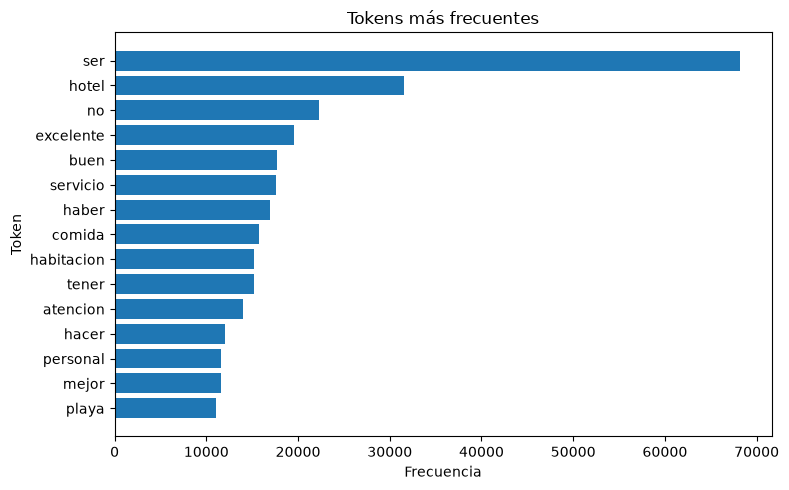

In [8]:
top_tokens = token_frequencies.head(15).sort_values('frequency')
plt.figure(figsize=(8, 5))
plt.barh(top_tokens['token'], top_tokens['frequency'])
plt.title('Tokens más frecuentes')
plt.xlabel('Frecuencia')
plt.ylabel('Token')
plt.tight_layout()
plt.show()


## 6. Construcción y filtrado de bigramas

In [9]:
# Código base del PDF
data['bigrams'] = data['tokenized_text_without_vocab'].apply(lambda tokens: [(tokens[i], tokens[i+1]) for i in range(len(tokens)-1)])
bigrams_positive = data[data['target'] == 1]['bigrams'].explode()
bigrams_negative = data[data['target'] == 0]['bigrams'].explode()
bigrams_positive_freq = bigrams_positive.value_counts().reset_index()
bigrams_negative_freq = bigrams_negative.value_counts().reset_index()
bigrams_positive_freq.columns = ['token', 'frequency']
bigrams_negative_freq.columns = ['token', 'frequency']

# Filtrar por frecuencia mayor a 10
# Complemento mínimo: si el dataset es pequeño, se usa el umbral definido arriba.
bigrams_positive_freq = bigrams_positive_freq[bigrams_positive_freq['frequency'] > MIN_FREQ]
bigrams_negative_freq = bigrams_negative_freq[bigrams_negative_freq['frequency'] > MIN_FREQ]

# Complemento mínimo: evitar vocabularios vacíos en datasets pequeños.
if bigrams_positive_freq.empty:
    bigrams_positive_freq = bigrams_positive.value_counts().reset_index()
    bigrams_positive_freq.columns = ['token', 'frequency']
if bigrams_negative_freq.empty:
    bigrams_negative_freq = bigrams_negative.value_counts().reset_index()
    bigrams_negative_freq.columns = ['token', 'frequency']

n = min(len(bigrams_positive_freq), len(bigrams_negative_freq))
bigrams_positive_freq = bigrams_positive_freq.nlargest(n, 'frequency')
bigrams_negative_freq = bigrams_negative_freq.nlargest(n, 'frequency')
bigrams_all = pd.concat([bigrams_positive_freq, bigrams_negative_freq], ignore_index=True)
bigrams_all = bigrams_all.sort_values('frequency', ascending=False).drop_duplicates(subset=['token'])
bigrams_all = bigrams_all.reset_index(drop=True)
bigrams = bigrams_all['token'].to_list()
data['bigrams_without_vocab'] = data['bigrams'].apply(lambda tokens: [t for t in tokens if t in bigrams])

bigrams_all.head(10)


,token,frequency
0,"(hotel, ser)",3978
1,"(ser, excelente)",3925
2,"(ser, mejor)",2966
3,"(punta, cana)",2586
4,"(ser, buen)",2382
5,"(excelente, servicio)",2379
6,"(buen, servicio)",1954
7,"(comida, ser)",1938
8,"(haber, ser)",1774
9,"(habitacion, ser)",1739


### Visualización: bigramas más frecuentes

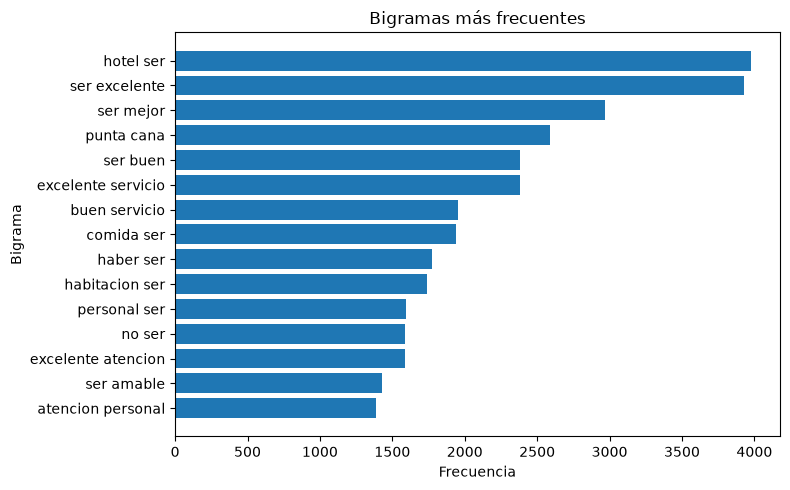

In [10]:
if not bigrams_all.empty:
    bigrams_plot = bigrams_all.head(15).copy()
    bigrams_plot['bigram'] = bigrams_plot['token'].apply(lambda x: ' '.join(x) if isinstance(x, tuple) else str(x))
    bigrams_plot = bigrams_plot.sort_values('frequency')
    plt.figure(figsize=(8, 5))
    plt.barh(bigrams_plot['bigram'], bigrams_plot['frequency'])
    plt.title('Bigramas más frecuentes')
    plt.xlabel('Frecuencia')
    plt.ylabel('Bigrama')
    plt.tight_layout()
    plt.show()
else:
    print('No se generaron bigramas suficientes para visualizar.')


## 7. Representación vectorial con TF-IDF aplicado a bigramas

In [11]:
# Complemento mínimo: en caso de que alguna reseña quede sin bigramas, se usa una marca auxiliar.
data['bigrams_without_vocab'] = data['bigrams_without_vocab'].apply(lambda x: x if len(x) > 0 else [('sin', 'bigrama')])

# Código base del PDF
tfidf_vectorizer = TfidfVectorizer(tokenizer=lambda x: x, preprocessor=lambda x: x, token_pattern=None)
tfidf_matrix = tfidf_vectorizer.fit_transform(data['bigrams_without_vocab'])
feature_names = tfidf_vectorizer.get_feature_names_out()
x = tfidf_matrix.toarray()
y = data['target'].values

print('Forma de la matriz TF-IDF:', x.shape)
print('Número de etiquetas:', y.shape)
print('Primeras características:', feature_names[:10])


Forma de la matriz TF-IDF: (34561, 2925)
Número de etiquetas: (34561,)
Primeras características: [['abierto' 'no']
 ['abrir' 'puerta']
 ['acabar' 'llegar']
 ['acceso' 'playa']
 ['acondicionado' 'habitacion']
 ['acondicionado' 'no']
 ['actividad' 'dia']
 ['actividad' 'entretenimiento']
 ['actividad' 'hacer']
 ['actividad' 'hotel']]


### Visualización: matriz TF-IDF

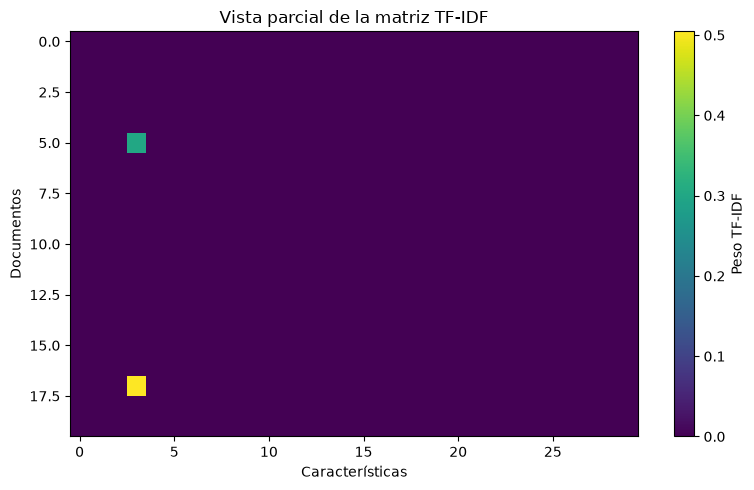

In [13]:
plt.figure(figsize=(8, 5))
plt.imshow(x[:min(20, x.shape[0]), :min(30, x.shape[1])], aspect='auto')
plt.title('Vista parcial de la matriz TF-IDF')
plt.xlabel('Características')
plt.ylabel('Documentos')
plt.colorbar(label='Peso TF-IDF')
plt.tight_layout()
plt.show()


## 8. Entrenamiento y evaluación con Regresión Logística

In [14]:
# Código base del PDF
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y)

log_reg = LogisticRegression(max_iter=1000, solver='lbfgs')
log_reg.fit(X_train, y_train)
y_pred = log_reg.predict(X_test)
y_proba = log_reg.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy: 0.9350499059742514

Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.51      0.64       786
           1       0.94      0.99      0.96      6127

    accuracy                           0.94      6913
   macro avg       0.90      0.75      0.80      6913
weighted avg       0.93      0.94      0.93      6913


Confusion Matrix:
 [[ 401  385]
 [  64 6063]]


### Visualización: matriz de confusión

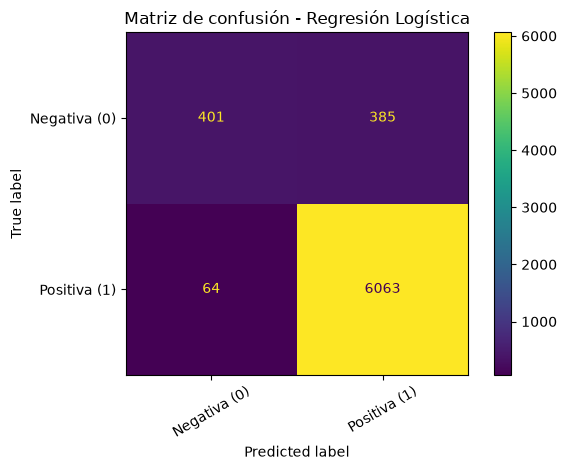

In [15]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negativa (0)', 'Positiva (1)'])
disp.plot(xticks_rotation=30)
plt.title('Matriz de confusión - Regresión Logística')
plt.tight_layout()
plt.show()


### Visualización: distribución de probabilidades de la clase positiva

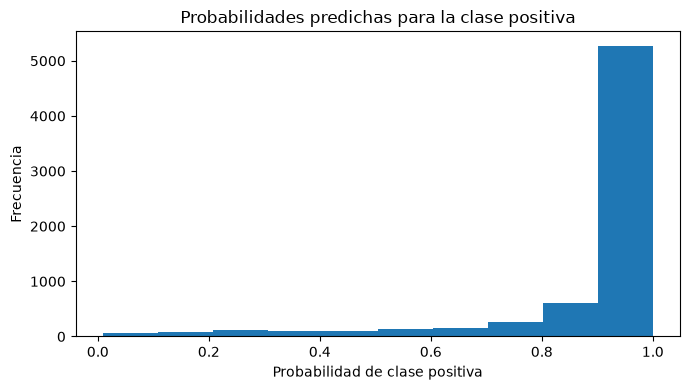

In [16]:
plt.figure(figsize=(7, 4))
plt.hist(y_proba, bins=10)
plt.title('Probabilidades predichas para la clase positiva')
plt.xlabel('Probabilidad de clase positiva')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()


## 9. SVM con validación cruzada

In [17]:
# Código base del PDF
from sklearn.model_selection import cross_val_score
from sklearn.svm import SVC

svm_model = SVC(kernel='poly', degree=3, C=1, random_state=42)
cv_scores = cross_val_score(svm_model, x, y, cv=3, scoring='f1', n_jobs=-1, verbose=1)
print(f"SVM Poligonal – f1 medio: {cv_scores.mean():.4f}, Desviación estándar: {cv_scores.std():.4f}")


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 32 concurrent workers.


SVM Poligonal – f1 medio: 0.9406, Desviación estándar: 0.0006


[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed: 76.9min finished


### Visualización: F1-score por pliegue

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(range(1, len(cv_scores) + 1), cv_scores, marker='o')
plt.title('F1-score por pliegue - SVM polinomial')
plt.xlabel('Pliegue')
plt.ylabel('F1-score')
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
